# ENDEKGAN-T2I V2 — PREPROCESSING SEBELUM EKSPERIMEN GAN

**PUBLIC NOTE:** Rendered Endek source/crop galleries are removed from saved outputs for public redistribution. These code cells regenerate the galleries using authorized local input data. All data folders and image/prompt metadata remain private.


**Notebook kerja preprocessing baru:** inventaris beberapa sumber Endek → deduplikasi → validasi kelas dan metadata prompt → split berdasarkan gambar sumber → perbandingan resize/crop → augmentasi berimbang → dua *experimental arms* → audit kesiapan pelatihan.

> **Status data:** arsip Mendeley dan Roboflow belum tersedia di direktori impor. Karena itu ukuran dataset penelitian baru **BELUM FINAL**. Notebook dapat dijalankan sekarang pada sumber lokal, sekaligus menerima sumber eksternal setelah diunduh dan diperiksa.

**Penegasan metodologis:** kenaikan **jumlah file** hasil resize, augmentasi, atau cropping tidak sama dengan kenaikan **jumlah gambar sumber independen**. Notebook menampilkan keduanya dengan nama yang berbeda. Empat kelas motif: **flora, fauna, dekoratif, geometris**. Model akhir tetap **Text-to-Image conditional GAN** dengan prompt CSV; evaluasi pakar atas gambar AI dilakukan setelah training dan generation.

**Implementasi:** membangun dua dataset manifest terpisah dari citra hasil preprocessing yang sudah dibuat:
- **A — full-image augmented:** 944 gambar training, 37 validation, 37 test.
- **B — crop-augmented ablation:** 944 training A + 336 crop 256×256 training-only = **1.280** training; validation dan test **tidak berubah**.

Dataset B merupakan **perlakuan eksperimental/provisional** untuk mengukur manfaat cropping, belum klaim bahwa setiap crop merepresentasikan motif utuh atau cocok dengan semua teks. Dataset eksternal harus melewati gerbang kurasi terlebih dahulu sebelum masuk training.

## 1. Konfigurasi environment D: dan direktori

Notebook tidak memindahkan atau menghapus gambar asli. Manifest baru ditulis ke `ENDEK_PREPROCESSING_V2`. Python, paket dan cache tetap pada `D:\VSCode-MultiAgent-AI`.

In [ ]:
from pathlib import Path
import os, io, json, csv, hashlib, zipfile, collections, random, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance, ImageFilter, ImageStat, ImageDraw
from IPython.display import display

BASE = Path(r"D:\DISERTASI_S3\WIWIK\EXPERIMEN_2")
RAW = BASE / "ENDEK_Dataset"
V1 = BASE / "ENDEK_AUGMENTED_V1"
CROP = BASE / "ENDEK_CROP_CANDIDATES_V2"
EXT = BASE / "EXTERNAL_ENDEK_DATASET_AUDIT"
OUT = BASE / "ENDEK_PREPROCESSING_V2"
SOURCE_META = V1 / "metadata_expert_guided_T2I_augmented_V1.csv"
CROP_SELECTED = CROP / "BALANCED_256_CROP_PROPOSAL_336_NOT_FOR_TRAINING_YET.csv"
CLASSES = ("flora","fauna","dekoratif","geometris")
SEED = 3407
IMAGE_SIZE = 256
REBUILD_IMAGE_FILES = False  # False: reuse verified preprocessing; do not duplicate thousands of JPGs
RELEASE_CROP_FOR_MAIN_TRAINING = False  # Crop remains a separate ablation arm.
OUT.mkdir(parents=True,exist_ok=True)
for directory in (RAW,V1,CROP,EXT):
    assert directory.is_dir(), directory
assert SOURCE_META.is_file() and CROP_SELECTED.is_file()
print("Working directory:",OUT)
print("Input metadata:",SOURCE_META.name)
print("Crop selection:",CROP_SELECTED.name)
print("A/B separation: ENABLED; GAN training: NOT started")

Working directory: D:\DISERTASI_S3\WIWIK\EXPERIMEN_2\ENDEK_PREPROCESSING_V2
Input metadata: metadata_expert_guided_T2I_augmented_V1.csv
Crop selection: BALANCED_256_CROP_PROPOSAL_336_NOT_FOR_TRAINING_YET.csv
A/B separation: ENABLED; GAN training: NOT started


## 2. Audit data aktual dan metadata Text-to-Image

Menghitung data yang **sudah tersedia**, bukan menjumlahkan angka yang tercantum di tiga situs publik. Semua turunan dari gambar sumber tetap memiliki identitas `source_sha256` dan *original prompt* yang sama.

In [ ]:
v1 = pd.read_csv(SOURCE_META, encoding="utf-8-sig",keep_default_na=False)
crop_selected = pd.read_csv(CROP_SELECTED,encoding="utf-8-sig",keep_default_na=False)
assert len(v1) == 1018 and len(crop_selected)==336
v1["is_aug_bool"] = v1["is_augmented"].astype(str).eq("1")
base_sources = v1.loc[~v1["is_aug_bool"]].copy()
assert base_sources.source_sha256.nunique()==len(base_sources)
assert all((v1.groupby("source_sha256")["split"].nunique())==1)
assert len(base_sources)==370  # ukuran koleksi baseline INTERNAL, bukan ukuran final sumber gabungan
assert v1["prompt"].astype(str).str.strip().ne("").all()
assert all(Path(p).is_file() for p in v1.image_path)
assert set(crop_selected.source_sha256).issubset(set(base_sources.source_sha256))
assert all(Path(p).is_file() for p in crop_selected.filename)
print("Koleksi internal yang tersedia:",len(base_sources),"sumber gambar independen")
print("Gambar setelah preprocessing full-image V1:",len(v1))
print("Kandidat crop seimbang yang disiapkan:",len(crop_selected))
print("Seluruh pasangan gambar–prompt full-image:",v1.prompt.astype(str).str.strip().ne("").sum())

Koleksi internal yang tersedia: 370 sumber gambar independen
Gambar setelah preprocessing full-image V1: 1018
Kandidat crop seimbang yang disiapkan: 336
Seluruh pasangan gambar–prompt full-image: 1018


## 3. Apakah ketiga dataset eksternal sudah tersedia?

Sumber yang dituju:
1. [Mendeley Multimodal Endek](https://data.mendeley.com/datasets/52ffyj9x3c/1)
2. [Mendeley Dataset Endek GAN](https://data.mendeley.com/datasets/9jwns77cg5/1)
3. [Roboflow Endek Annotated](https://universe.roboflow.com/ayu-menuh-rhmpz/endek-dataset-anoted-multi-iobno)

File ZIP/gambar harus diletakkan pada `EXTERNAL_ENDEK_DATASET_AUDIT/incoming/{mendeley_multimodal,mendeley_gan,roboflow_multi}`. Notebook ini membaca gambar dalam ZIP tanpa mengekstrak ke drive C:. **File baru tidak akan diikutkan otomatis ke training tanpa deduplikasi dan metadata prompt.**

In [ ]:
INCOMING = EXT/"incoming"
SOURCE_FOLDERS = {
    "mendeley_multimodal":INCOMING/"mendeley_multimodal",
    "mendeley_gan":INCOMING/"mendeley_gan",
    "roboflow_multi":INCOMING/"roboflow_multi",
}
ext_inputs={}
for label,folder in SOURCE_FOLDERS.items():
    folder.mkdir(parents=True,exist_ok=True)
    files=[p for p in folder.rglob("*") if p.is_file()]
    ext_inputs[label]=files
    print(f"{label}: {len(files)} arsip/file, {sum(p.stat().st_size for p in files)/1024**2:.2f} MiB")
external_files_present=any(ext_inputs.values())
print("Sumber eksternal siap diaudit?" ,external_files_present)
if not external_files_present:
    print("BELUM. Finalisasi dataset gabungan ditahan; tidak mengarang jumlah tambahan gambar independen.")

mendeley_multimodal: 0 arsip/file, 0.00 MiB
mendeley_gan: 0 arsip/file, 0.00 MiB
roboflow_multi: 0 arsip/file, 0.00 MiB
Sumber eksternal siap diaudit? False
BELUM. Finalisasi dataset gabungan ditahan; tidak mengarang jumlah tambahan gambar independen.


## 4. Inventaris dan deduplikasi sumber eksternal: SHA-256 + dHash

Kode berikut juga menangani gambar yang tersimpan dalam ZIP dan memeriksa kemiripan visual dengan gambar pada koleksi internal. **dHash hanya penanda kandidat kemiripan, bukan bukti bahwa dua motif sama.**

Roboflow merupakan dataset deteksi objek; struktur foldernya mungkin tidak menyediakan kelas motif secara langsung. Gambar yang belum memiliki kelas atau pasangan teks akan ditandai **PENDING_METADATA**.

In [ ]:
IMAGE_EXTS={".jpg",".jpeg",".png",".webp",".bmp",".tif",".tiff"}
MAX_BYTES=30_000_000
def dhash_image(image):
    g=ImageOps.grayscale(image).resize((9,8),Image.Resampling.LANCZOS)
    pixels=list(g.getdata())
    key=0
    for y in range(8):
        for x in range(8):
            key=(key<<1)|int(pixels[9*y+x]>pixels[9*y+x+1])
    return key
def inspect_bytes(data,label,filename):
    try:
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            w,h=im.size
            dh=dhash_image(im)
        dirs=[x.lower() for x in filename.replace("\\","/").split("/")[:-1]]
        infer={x for x in dirs if x in CLASSES}
        category=next(iter(infer)) if len(infer)==1 else "UNMAPPED"
        return dict(origin=label,filename=filename,sha256=hashlib.sha256(data).hexdigest(),
                    dhash=format(dh,"016x"),width=w,height=h,
                    motif_class=category,bytes=len(data),status="PENDING_METADATA")
    except Exception as exc:
        return dict(origin=label,filename=filename,error=str(exc)[:250])
def read_external_candidates():
    rows=[]
    for origin,paths in ext_inputs.items():
        for file in paths:
            if file.suffix.lower() in IMAGE_EXTS:
                if file.stat().st_size<=MAX_BYTES:
                    rows.append(inspect_bytes(file.read_bytes(),origin,str(file.relative_to(SOURCE_FOLDERS[origin]))))
            elif file.suffix.lower()==".zip":
                try:
                    with zipfile.ZipFile(file) as package:
                        for entry in package.infolist():
                            if entry.is_dir() or Path(entry.filename).suffix.lower() not in IMAGE_EXTS:
                                continue
                            if entry.file_size>MAX_BYTES:continue
                            with package.open(entry) as stream:
                                data=stream.read(MAX_BYTES+1)
                            if len(data)<=MAX_BYTES:
                                rows.append(inspect_bytes(data,origin,file.name+"/"+entry.filename))
                except Exception as exc:
                    rows.append(dict(origin=origin,filename=file.name,error="ZIP: "+str(exc)[:250]))
    return pd.DataFrame(rows)
external_scan=read_external_candidates()
reference_hashes=set(base_sources.source_sha256)
reference_dhash=[]
for rel in base_sources.source_filename:
    with Image.open(RAW/rel) as image:
        reference_dhash.append(dhash_image(image))
if external_scan.empty:
    print("Belum ada gambar eksternal untuk dipindai.")
else:
    external_scan["duplicate_sha256_internal"] = external_scan.sha256.isin(reference_hashes)
    external_scan["closest_dhash_distance"] = external_scan.dhash.map(
        lambda h:min((int(h,16)^v).bit_count() for v in reference_dhash)
        if isinstance(h,str) and len(h)==16 else None)
    external_scan["visual_near_duplicate_review"] = external_scan.closest_dhash_distance.le(4)
    display(external_scan.groupby("origin").agg(
        files=("filename","count"),
        exact_duplicates=("duplicate_sha256_internal","sum"),
        near_matches=("visual_near_duplicate_review","sum")
    ))
external_scan.to_csv(OUT/"external_candidate_inventory.csv",index=False,encoding="utf-8-sig")

D:\VSCode-MultiAgent-AI\caches\temp\ipykernel_6436\1282786142.py:5: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels=list(g.getdata())


Belum ada gambar eksternal untuk dipindai.


## 5. Identitas sumber dan pembagian data yang bebas kebocoran

Pembagian harus dilakukan pada **gambar sumber**, sebelum menghasilkan crop/augmentasi. Jika ada sumber eksternal baru yang lolos audit dan memiliki prompt, seluruh sumber perlu *re-split* (seed tetap) sehingga seluruh turunannya berada dalam split yang sama.

Sampai validasi sumber eksternal selesai, dua lengan dataset A/B memakai pembagian internal 296/37/37 yang sama agar perbandingan adil.

In [ ]:
source_split=base_sources[["source_sha256","source_filename","label","class_idx","split","prompt"]].copy()
assert len(source_split)==len(set(source_split.source_sha256))
assert set(source_split.split)=={"train","val","test"}
print(pd.crosstab(source_split.label,source_split.split).reindex(index=CLASSES,fill_value=0))
source_split.to_csv(OUT/"internal_source_split_reference.csv",index=False,encoding="utf-8-sig")
def create_stratified_source_split(items,seed=3407):
    """For a newly curated source pool only; group all visually related images."""
    needed={"sha256","label","prompt","path","visual_group_id"}
    if not needed.issubset(items.columns):
        raise ValueError("Curated pool requires SHA, label, prompt, path, visual_group_id")
    if items["sha256"].duplicated().any():
        raise ValueError("Deduplicate SHA-256 identical source files before splitting")
    if not items["label"].isin(CLASSES).all():
        raise ValueError("Unmapped motif categories cannot enter T2I train/val/test")
    if items["prompt"].astype(str).str.strip().eq("").any():
        raise ValueError("Source images require mapped text descriptions")
    if items["visual_group_id"].astype(str).str.strip().eq("").any():
        raise ValueError("Missing visual_group_id; inspect dHash-near pairs first")
    if (items.groupby("visual_group_id")["label"].nunique()>1).any():
        raise ValueError("Visual groups cross class labels; resolve before splitting")
    rng=random.Random(seed)
    assignments={}
    for label in CLASSES:
        subset=items[items.label==label]
        groups=[(str(k),list(g["sha256"])) for k,g in subset.groupby("visual_group_id")]
        rng.shuffle(groups)
        n=len(subset)
        target_train=round(.8*n)
        target_val=round(.1*n)
        totals={"train":0,"val":0,"test":0}
        for visual_id,source_ids in groups:
            if totals["train"]<target_train:
                sp="train"
            elif totals["val"]<target_val:
                sp="val"
            else:
                sp="test"
            for identifier in source_ids:
                assignments[identifier]=sp
            totals[sp]+=len(source_ids)
    result=items.assign(split=items.sha256.map(assignments))
    assert result.groupby("visual_group_id")["split"].nunique().max()==1
    return result
print("Metode split gabungan tersedia, namun belum dieksekusi karena sumber eksternal belum tervalidasi.")

split      test  train  val
label                      
flora        15    118   14
fauna         5     42    6
dekoratif    11     90   11
geometris     6     46    6
Metode split gabungan tersedia, namun belum dieksekusi karena sumber eksternal belum tervalidasi.


## 6. Visualisasi: gambar penuh, resize dan cropping pada keempat kelas

Crop **kontekstual 448×448 → 256×256** mempertahankan lebih banyak komposisi. Crop **384×384 → 256×256** dan patch lokal **128×128** menekankan tekstur tetapi lebih berisiko memotong bentuk ornamen. Keempat kelas memerlukan pemeriksaan kesesuaian prompt dan tata letak.

Galeri berasal dari **gambar Endek sebenarnya** yang ada pada drive D, bukan keluaran GAN.

In [ ]:
crop_manifest=pd.read_csv(CROP/"crop_candidate_manifest.csv",encoding="utf-8-sig",keep_default_na=False)
assert len(crop_manifest)==1184
gallery=[]
for cl in CLASSES:
    row=crop_manifest[crop_manifest["class"]==cl].iloc[0]
    rel=row.source_filename
    items=crop_manifest[(crop_manifest["source_sha256"]==row.source_sha256)]
    full=ImageOps.exif_transpose(Image.open(RAW/rel)).convert("RGB")
    variants={"Asli 512":full, "Resize 256":full.resize((256,256),Image.Resampling.LANCZOS)}
    for key,title in [("context448","Crop kontekstual"),("texture384","Crop tekstur"),("local128_1","Patch lokal")]:
        match=items.loc[items["crop_variant"]==key]
        if len(match): variants[title]=Image.open(match.iloc[0]["filename"]).convert("RGB")
    gallery.append((cl,variants))
fig,axes=plt.subplots(4,5,figsize=(15,12))
for i,(cl,views) in enumerate(gallery):
    for j,(label,img) in enumerate(views.items()):
        axes[i,j].imshow(img)
        axes[i,j].axis("off")
        if i==0:axes[i,j].set_title(label,fontweight="bold",fontsize=10)
    axes[i,0].set_ylabel(cl.capitalize(),fontsize=12,fontweight="bold")
fig.suptitle("Audit preprocessing Endek: citra penuh vs cropping (contoh nyata)",fontsize=15,fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Reusable preprocessing functions: resize, cropping, augmentasi fotometrik

Fungsi ini dapat digunakan ulang ketika **sumber eksternal yang unik, berizin, dan sudah punya prompt** telah digabungkan. Contoh operasi dilakukan pada memori; file sumber tidak ditimpa. Crop tekstur masih heuristik. **Tidak diterapkan otomatis untuk mengklaim kebenaran bentuk ornamen.**

In [ ]:
def resize_full(image,size=256):
    return image.convert("RGB").resize((size,size),Image.Resampling.LANCZOS)
def select_texture_roi(image,side=384):
    if image.size!=(512,512):raise ValueError("Crop example assumes 512x512 source")
    positions=sorted(set([0,(512-side)//2,512-side]))
    candidates=[]
    for y in positions:
        for x in positions:
            roi=(x,y,x+side,y+side)
            small=image.crop(roi).convert("L").resize((96,96),Image.Resampling.BILINEAR)
            edge=ImageStat.Stat(small.filter(ImageFilter.FIND_EDGES)).mean[0]
            contrast=ImageStat.Stat(small).stddev[0]
            score=.8*edge+.2*contrast
            candidates.append((score,roi))
    return sorted(candidates,key=lambda z:(-z[0],z[1]))[0][1]
def make_photometric_variant(image,seed):
    rng=random.Random(seed)
    aug=ImageEnhance.Brightness(image).enhance(rng.uniform(.935,1.065))
    aug=ImageEnhance.Contrast(aug).enhance(rng.uniform(.945,1.055))
    aug=ImageEnhance.Color(aug).enhance(rng.uniform(.965,1.035))
    aug=ImageEnhance.Sharpness(aug).enhance(rng.uniform(.88,1.16))
    return aug
example=ImageOps.exif_transpose(Image.open(RAW/base_sources.iloc[0].source_filename)).convert("RGB")
roi=select_texture_roi(example)
preview=[example,resize_full(example),resize_full(example.crop(roi)),make_photometric_variant(resize_full(example),SEED)]
fig,axes=plt.subplots(1,4,figsize=(12,3.2))
for ax,img,name in zip(axes,preview,["Sumber","Resize","Crop tekstur","Augmentasi warna"]):
    ax.imshow(img);ax.axis("off");ax.set_title(name)
plt.tight_layout()
plt.show()
print("Contoh koordinat candidate crop:",roi)

Contoh koordinat candidate crop: (64, 64, 448, 448)


## 8. Statistik V1 dan kandidat penambahan cropping

Crop yang dipilih sebanyak **336** (84 per kelas) dibuat hanya dari data training. Untuk memperoleh perlakuan B, metadata crop digabungkan pada manifest terpisah, **tanpa menyalin gambar ke folder lain**. Ini bukan penggabungan gambar sumber eksternal.

,Training source (resize),Augmentasi fotometrik,Training full-image A,Crop tambahan B,Training crop arm B
flora,118,118,236,84,320
fauna,42,194,236,84,320
dekoratif,90,146,236,84,320
geometris,46,190,236,84,320


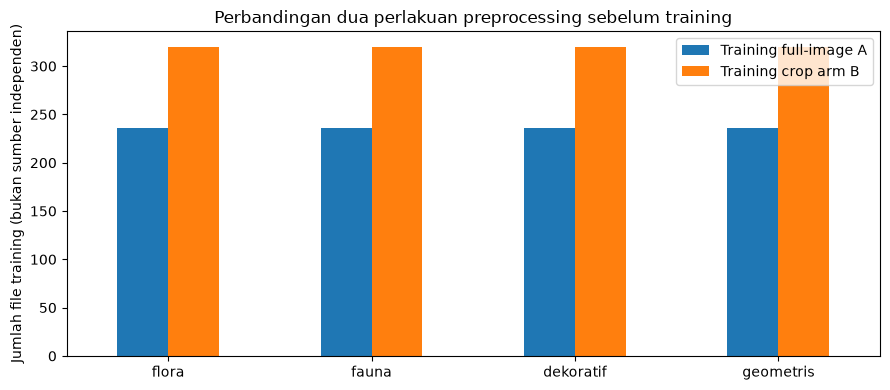

In [ ]:
v1_train = v1[v1.split=="train"].groupby("label").size().reindex(CLASSES,fill_value=0)
v1_orig = base_sources[base_sources.split=="train"].groupby("label").size().reindex(CLASSES,fill_value=0)
new_aug = v1_train-v1_orig
crop_count = crop_selected.groupby("class").size().reindex(CLASSES,fill_value=0)
counts=pd.DataFrame({
    "Training source (resize)":v1_orig,
    "Augmentasi fotometrik":new_aug,
    "Training full-image A":v1_train,
    "Crop tambahan B":crop_count,
    "Training crop arm B":v1_train+crop_count,
})
display(counts)
assert counts["Training full-image A"].sum()==944
assert counts["Crop tambahan B"].sum()==336
assert counts["Training crop arm B"].sum()==1280
ax=counts[["Training full-image A","Training crop arm B"]].plot.bar(
    figsize=(9,4),rot=0,title="Perbandingan dua perlakuan preprocessing sebelum training")
ax.set_ylabel("Jumlah file training (bukan sumber independen)")
plt.tight_layout();plt.show()

## 9. Bentuk dataset B: full-image + crop ablation (manifest aktual)

**Eksekusi yang dilakukan di sini:** membuat manifest tambahan **1.354 gambar** (1.280 train + 37 validation + 37 test), semuanya menunjuk ke file nyata yang sudah ada. **Tidak ada training GAN dijalankan.** Kondisi crop ditandai sebagai **EXPERIMENTAL**, dan prompt asli diwariskan dengan `prompt_semantic_verified=false`. Penilaian pakar motif hasil GAN tetap dijadwalkan di tahap akhir.

Pemisahan arm A/B mempertahankan sumber, validation dan test yang sama; evaluasi perbandingan tetap memerlukan *equal optimizer updates*.

In [ ]:
source_lookup=v1.groupby("source_sha256",sort=False).first()
new_rows=[]
for _,item in crop_selected.iterrows():
    source=str(item["source_sha256"])
    assert source in source_lookup.index
    src=source_lookup.loc[source].to_dict()
    src["source_sha256"]=source
    assert src["split"]=="train" and src["label"]==item["class"]
    outrow=src.copy()
    outrow["image_path"]=str(item["filename"])
    outrow["filename"]="CROP_ABLATION/"+str(item["output_relative_path"])
    outrow["split"]="train"
    outrow["augmentation_variant"]="crop_"+str(item["crop_variant"])
    outrow["augmentation_recipe"]="heuristic_motif_crop_for_ablation"
    outrow["is_augmented"]=1
    outrow["is_aug_bool"]=True
    outrow["width"]=256
    outrow["height"]=256
    outrow["prompt_semantic_verified"]="false"
    outrow["is_crop"]=True
    outrow["training_arm_status"]="EXPERIMENTAL_CROP_ABLATION"
    outrow["crop_roi_status"]="HEURISTIC_NOT_SEMANTICALLY_VERIFIED"
    new_rows.append(outrow)
arm_A=v1.copy()
arm_A["is_crop"]=False
arm_A["training_arm_status"]="FULL_IMAGE_A"
arm_A["crop_roi_status"]="NOT_APPLICABLE"
arm_B=pd.concat([arm_A,pd.DataFrame(new_rows)],ignore_index=True)
assert len(arm_A)==1018 and len(arm_B)==1354
assert arm_B.groupby("split").size().to_dict()=={"train":1280,"val":37,"test":37}
assert arm_B["source_sha256"].astype(str).str.fullmatch(r"[0-9a-f]{64}").all()
assert arm_B.groupby("source_sha256")["split"].nunique().max()==1
assert arm_B[arm_B["is_crop"]]["split"].eq("train").all()
assert arm_B[arm_B.is_crop]["label"].value_counts().reindex(CLASSES).eq(84).all()
assert set(arm_B[arm_B.is_crop].source_sha256).issubset(set(source_lookup.index))
assert arm_B["image_path"].map(lambda p:Path(p).is_file()).all()
assert (arm_A.loc[arm_A.split=="test","source_sha256"].tolist() ==
        arm_B.loc[arm_B.split=="test","source_sha256"].tolist())
print("A full-image: ",arm_A.groupby("split").size().to_dict())
print("B crop ablation:",arm_B.groupby("split").size().to_dict())
print("Jenis B: EXPERIMENTAL, bukan dataset baru yang diklaim telah tervalidasi.")

A full-image:  {'test': 37, 'train': 944, 'val': 37}
B crop ablation: {'test': 37, 'train': 1280, 'val': 37}
Jenis B: EXPERIMENTAL, bukan dataset baru yang diklaim telah tervalidasi.


## 10. Tulis manifest preprocessing dan metadata prompt untuk kedua arm

Manifest disimpan dalam folder baru `ENDEK_PREPROCESSING_V2` dan dapat dibaca oleh data loader EndekGAN-T2I menggunakan kolom `image_path`, `prompt`, `label`, `class_idx`, `source_sha256`, dan `split`. Semua file citra tetap berada di lokasi sebelumnya untuk menghindari duplikasi penyimpanan.

In [ ]:
def export_arm(df,name):
    target=OUT/"arms"/name
    target.mkdir(exist_ok=True,parents=True)
    keep=df.drop(columns=["is_aug_bool"],errors="ignore")
    for sp in ("train","val","test"):
        rows=keep[keep.split==sp]
        assert len(rows)>0
        rows.to_csv(target/(sp+"_split.csv"),index=False,encoding="utf-8-sig")
    keep.to_csv(target/"metadata_all_splits.csv",index=False,encoding="utf-8-sig")
    return target
arm_dir_A=export_arm(arm_A,"full_image_augmented_A")
arm_dir_B=export_arm(arm_B,"full_plus_crop_ablation_B")
report_counts={
    "full_image_augmented_A":{"train":944,"validation":37,"test":37,"total":1018},
    "full_plus_crop_ablation_B":{"train":1280,"validation":37,"test":37,"total":1354},
    "source_pool_is_provisional":not external_files_present,
    "external_added_unique_sources":0 if not external_files_present else "PENDING_AUDIT",
    "crop_quality_status":"HEURISTIC_CANDIDATES_UNVERIFIED",
    "train_test_source_leakage_detected":False,
    "training_started":False
}
(OUT/"dataset_arm_counts.json").write_text(json.dumps(report_counts,indent=2,ensure_ascii=False),encoding="utf-8")
print("Arm A:",arm_dir_A)
print("Arm B:",arm_dir_B)

Arm A: D:\DISERTASI_S3\WIWIK\EXPERIMEN_2\ENDEK_PREPROCESSING_V2\arms\full_image_augmented_A
Arm B: D:\DISERTASI_S3\WIWIK\EXPERIMEN_2\ENDEK_PREPROCESSING_V2\arms\full_plus_crop_ablation_B


## 11. Quality assurance: duplikasi, leakage, resolusi dan prompt

QA akhir membedakan **kesesuaian struktural** (dapat diverifikasi otomatis) dan **kesesuaian semantik desain** (belum terbukti dari checksum saja). Tidak melakukan filter pakar di awal; pakar akan menilai gambar GAN di akhir. Cropping tetap dibandingkan sebagai faktor eksperimen, bukan dinyatakan lebih baik sebelum ada hasil.

In [ ]:
def qa_report(df,arm):
    assert df.image_path.map(lambda x:Path(x).is_file()).all()
    assert df.prompt.astype(str).str.strip().ne("").all()
    assert df.label.isin(CLASSES).all()
    assert df["source_sha256"].astype(str).str.fullmatch(r"[0-9a-f]{64}").all()
    assert df.groupby("source_sha256").split.nunique().max()==1
    assert df.loc[df.split!="train","is_crop"].eq(False).all()
    split_ids={s:set(df.loc[df.split==s,"source_sha256"]) for s in ("train","val","test")}
    assert not (split_ids["train"]&split_ids["val"])
    assert not (split_ids["train"]&split_ids["test"])
    assert not (split_ids["val"]&split_ids["test"])
    train_counts=df[df.split=="train"].label.value_counts().reindex(CLASSES,fill_value=0)
    assert train_counts.nunique()==1
    return {"arm":arm,"files":len(df),"train":int((df.split=="train").sum()),
           "val":int((df.split=="val").sum()),"test":int((df.split=="test").sum()),
           "source_groups":df.source_sha256.nunique(),
           "train_per_class":train_counts.to_dict(),"passed_structural_checks":True}
qa={"arm_A":qa_report(arm_A,"A"),"arm_B":qa_report(arm_B,"B")}
assert qa["arm_A"]["source_groups"]==qa["arm_B"]["source_groups"]
(OUT/"pretraining_quality_report.json").write_text(json.dumps(qa,indent=2,ensure_ascii=False),encoding="utf-8")
print(json.dumps(qa,ensure_ascii=False,indent=2))

{
  "arm_A": {
    "arm": "A",
    "files": 1018,
    "train": 944,
    "val": 37,
    "test": 37,
    "source_groups": 370,
    "train_per_class": {
      "flora": 236,
      "fauna": 236,
      "dekoratif": 236,
      "geometris": 236
    },
    "passed_structural_checks": true
  },
  "arm_B": {
    "arm": "B",
    "files": 1354,
    "train": 1280,
    "val": 37,
    "test": 37,
    "source_groups": 370,
    "train_per_class": {
      "flora": 320,
      "fauna": 320,
      "dekoratif": 320,
      "geometris": 320
    },
    "passed_structural_checks": true
  }
}


## 12. Flowchart preprocessing sebelum GAN

Alur dimulai dari koleksi gabungan **setelah akses sumber eksternal tersedia**. Jika penambahan gambar baru terjadi, audit dan split harus dilakukan ulang. Hingga saat ini arm A/B merupakan perbandingan perlakuan atas koleksi internal yang tersedia.

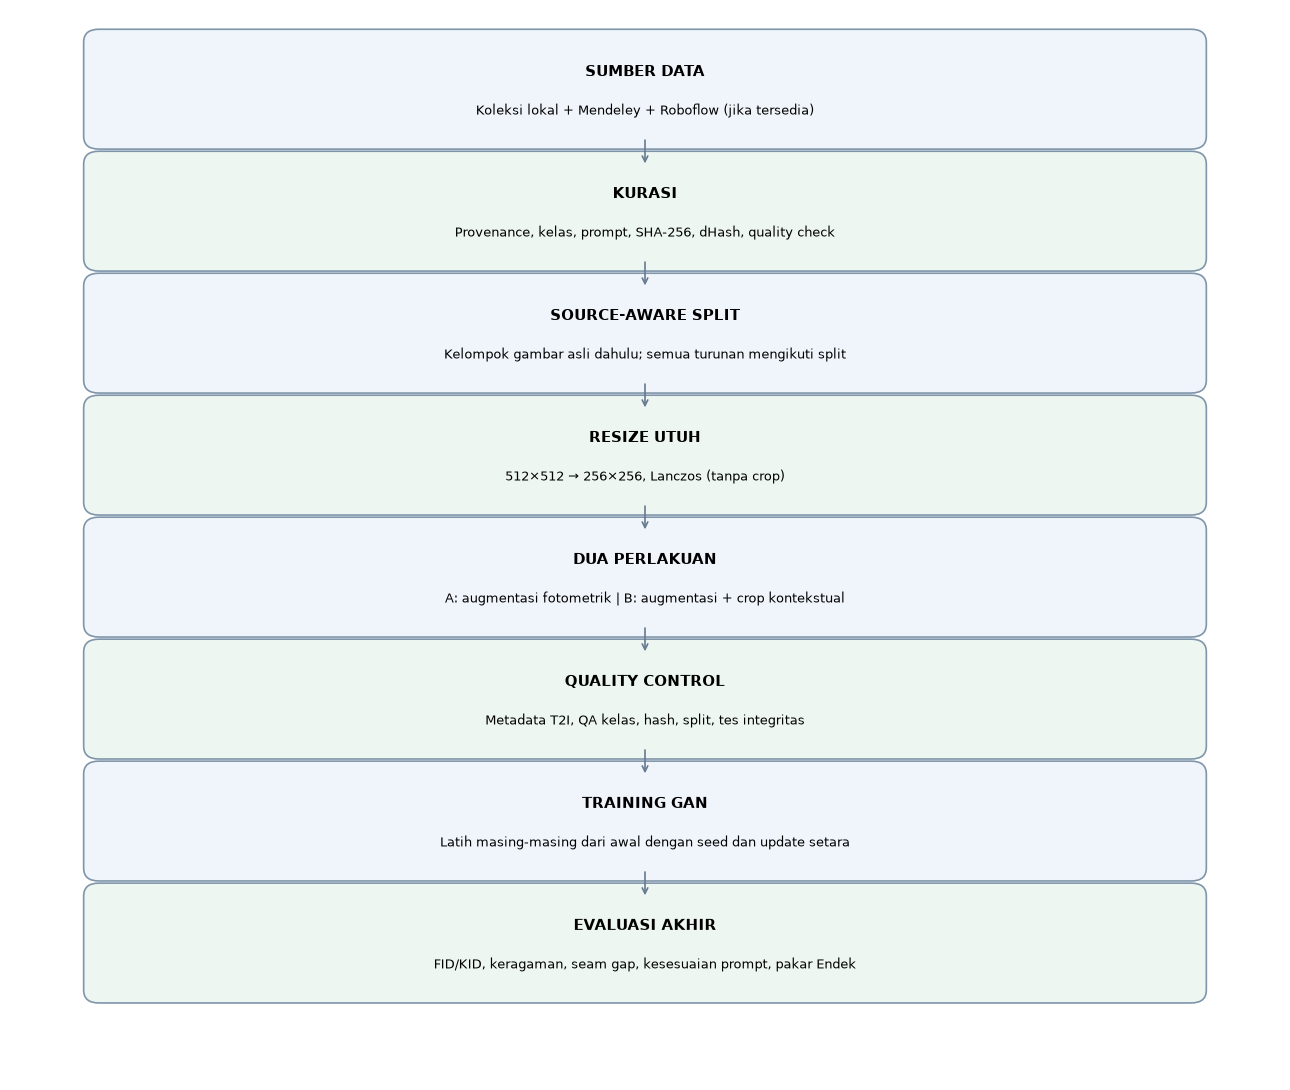

In [ ]:
from matplotlib.patches import FancyBboxPatch
steps=[
("SUMBER DATA","Koleksi lokal + Mendeley + Roboflow (jika tersedia)"),
("KURASI","Provenance, kelas, prompt, SHA-256, dHash, quality check"),
("SOURCE-AWARE SPLIT","Kelompok gambar asli dahulu; semua turunan mengikuti split"),
("RESIZE UTUH","512×512 → 256×256, Lanczos (tanpa crop)"),
("DUA PERLAKUAN","A: augmentasi fotometrik | B: augmentasi + crop kontekstual"),
("QUALITY CONTROL","Metadata T2I, QA kelas, hash, split, tes integritas"),
("TRAINING GAN","Latih masing-masing dari awal dengan seed dan update setara"),
("EVALUASI AKHIR","FID/KID, keragaman, seam gap, kesesuaian prompt, pakar Endek")
]
fig,ax=plt.subplots(figsize=(13,11))
ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis("off")
for i,(title,subtitle) in enumerate(steps):
    y=.96-i*.114
    fill="#F0F5FB" if i%2==0 else "#EDF6F0"
    box=FancyBboxPatch((.07,y-.078),.86,.088,boxstyle="round,pad=0.012,rounding_size=0.012",
                       facecolor=fill,edgecolor="#7F95AA",lw=1.2)
    ax.add_patch(box)
    ax.text(.5,y-.018,title,ha="center",va="center",weight="bold",fontsize=11)
    ax.text(.5,y-.054,subtitle,ha="center",va="center",fontsize=9)
    if i<len(steps)-1:
        ax.annotate("",xy=(.5,y-.106),xytext=(.5,y-.079),
                    arrowprops=dict(arrowstyle="->",lw=1.2,color="#677A90"))
plt.tight_layout()
fig.savefig(OUT/"FLOWCHART_PREPROCESSING_V2.png",dpi=160,bbox_inches="tight")
plt.show()

## 13. Kesiapan sebelum training dan reproduksibilitas

*Gerbang data utama:* dataset eksternal yang baru disebutkan harus benar-benar tersedia, terdeduplikasi, dapat dipetakan ke empat kelas dan mempunyai deskripsi teks yang sesuai sebelum klaim **dataset gabungan yang lebih besar** ditetapkan.

*Gerbang model:* V2 menggunakan model EndekGAN-T2I sebelumnya sebagai **arsitektur acuan**, tetapi checkpoint baru harus dilatih ulang dari awal. Tidak ada hasil FID/KID baru sebelum training.

*Interpretasi eksperimen B:* crop diberi metadata asli untuk menguji dampak perlakuan tersebut. Kecocokan prompt dengan crop dan identitas ornament tidak dijamin secara otomatis; justru harus diukur pada evaluasi T2I, sebelum mengklaim peningkatan kualitas.

In [ ]:
ready={
  "data_stage":"PREPROCESSING_ARMS_BUILT_FROM_AVAILABLE_DATA",
  "external_dataset_source_files_present":bool(external_files_present),
  "final_merged_dataset_ready":False,
  "metadata_from_original_csv_preserved":True,
  "A_full_image_train":944,
  "B_crop_ablation_train":1280,
  "identical_validation_and_test":True,
  "classes":list(CLASSES),
  "cropping": "EXPERIMENTAL_ARM_ONLY; TEXT_ALIGNMENT_NOT_PROVEN",
  "new_GAN_training_started":False,
  "expert_scoring":"AFTER_GENERATED_OUTPUTS",
  "requires_before_expanded_final": [
      "download external dataset files on D drive",
      "verify project licenses, source provenance, class labels",
      "deduplicate across sources using SHA-256 and visual similarity review",
      "map metadata prompts for every new source",
      "make new source-aware splits and rerun preprocessing arms"
  ]
}
(OUT/"PRE_EXPERIMENT_STATUS.json").write_text(json.dumps(ready,indent=2,ensure_ascii=False),encoding="utf-8")
print(json.dumps(ready,indent=2,ensure_ascii=False))

{
  "data_stage": "PREPROCESSING_ARMS_BUILT_FROM_AVAILABLE_DATA",
  "external_dataset_source_files_present": false,
  "final_merged_dataset_ready": false,
  "metadata_from_original_csv_preserved": true,
  "A_full_image_train": 944,
  "B_crop_ablation_train": 1280,
  "identical_validation_and_test": true,
  "classes": [
    "flora",
    "fauna",
    "dekoratif",
    "geometris"
  ],
  "cropping": "EXPERIMENTAL_ARM_ONLY; TEXT_ALIGNMENT_NOT_PROVEN",
  "new_GAN_training_started": false,
  "expert_scoring": "AFTER_GENERATED_OUTPUTS",
  "requires_before_expanded_final": [
    "download external dataset files on D drive",
    "verify project licenses, source provenance, class labels",
    "deduplicate across sources using SHA-256 and visual similarity review",
    "map metadata prompts for every new source",
    "make new source-aware splits and rerun preprocessing arms"
  ]
}


## Kesimpulan

**Notebook preprocessing dibuat dan dapat dijalankan sebelum eksperimen GAN.** Output aktual: dua lengan preprocessing dengan **1.018** dan **1.354** file, menggunakan split evaluasi yang sama. Angka ini adalah **jumlah file hasil perlakuan**, bukan ukuran dataset gambar Endek independen gabungan.

Proses ekspansi melalui dua Mendeley dan satu Roboflow **belum selesai** sampai berkas gambar benar-benar diterima dan diperiksa. Ketika data eksternal tersedia, tahap inventaris/deduplikasi/prompt/split di notebook harus dijalankan kembali, baru menetapkan jumlah dataset baru untuk paper. Tahap pakar ditempatkan **di akhir** untuk menilai hasil generasi AI.